In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Part 1**

In [10]:
chrw = pd.read_csv('data_ws2026/CHRW.csv')
fdx = pd.read_csv('data_ws2026/FDX.csv')
googl = pd.read_csv('data_ws2026/GOOGL.csv')
ip = pd.read_csv('data_ws2026/IP.csv')
lly = pd.read_csv('data_ws2026/LLY.csv')

chrw['Ticker'] = 'CHRW'
fdx['Ticker'] = 'FDX'
googl['Ticker'] = 'GOOGL'
ip['Ticker'] = 'IP'
lly['Ticker'] = 'LLY'

stocks = pd.concat([chrw, fdx, googl, ip, lly])
stocks['Date'] = pd.to_datetime(stocks['Date'], errors="coerce")
stocks = stocks.set_index('Date').sort_index()  
stocks.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,97.954,99.193,96.320,96.859,1383200,0.0,0.0,CHRW
2022-01-03,37.651,37.810,37.095,37.206,2808400,0.0,0.0,IP
2022-01-03,143.688,144.476,142.358,143.625,28646000,0.0,0.0,GOOGL
2022-01-03,262.766,262.766,255.728,260.200,2621300,0.0,0.0,LLY
2022-01-03,190.021,191.403,187.944,189.107,2174728,0.0,0.0,FDX


1. (2 pt) Is there a company that has no difference between the High and Low columns
for any trading day? What does it mean for the stock’s trading behavior on such
days?

2. (1 pt) What is the highest and lowest price price each company recorded? Hint:
Select the column(s) that can contain the maximum and minimum price wisely.


In [13]:
pd.DataFrame({'Highest price': stocks.groupby('Ticker')['High'].max(),
              'Lowest price': stocks.groupby('Ticker')['High'].min()})

,Highest price,Lowest price
Ticker,,
CHRW,166.040,65.358
FDX,241.786,107.979
GOOGL,327.977,85.704
IP,55.189,25.254
LLY,1105.302,227.775


Calculate logarithmic returns from Close. For each company, report min,
max, mean, standard deviation, and skewness of returns.


In [85]:
stocks['log_ret'] = np.log(stocks.groupby('Ticker')['Close'].pct_change().add(1))
pd.DataFrame({'Mean': stocks['log_ret'].mean(),
              'Std': stocks['log_ret'].std(),
              'Min': stocks['log_ret'].min(),
              'Max': stocks['log_ret'].max()})

ValueError: If using all scalar values, you must pass an index

4 . (2 pt) When (date) did each company record the second highest gain and second
highest loss (in terms of logarithmic returns)? Hint: idxmax.


In [19]:
stocks.groupby('Ticker').idxmax()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Ticker,,,,,,,
CHRW,2025-12-22,2025-12-22,2025-12-24,2025-12-19,2024-03-15,2025-12-05,2022-01-03
FDX,2024-07-17,2024-07-16,2024-07-17,2024-07-16,2022-09-16,2025-06-23,2022-01-03
GOOGL,2025-11-25,2025-11-25,2025-12-05,2025-11-25,2025-05-07,2025-06-09,2022-07-18
IP,2024-11-25,2024-11-25,2024-11-25,2025-01-24,2025-02-04,2022-02-17,2022-01-03
LLY,2025-11-26,2025-11-26,2025-11-26,2025-11-25,2025-08-07,2025-02-14,2022-01-03


5. (2 pt) What is the median calendar weekly volume (i.e. sum of volume for a particular week) for each company? Hint: check resample.

In [22]:
weekly = stocks.groupby('Ticker')['Volume'].resample("W").mean()
pd.DataFrame({'Median weekly volume': weekly.groupby('Ticker').median(),
              'Date': weekly.groupby('Ticker').idxmax()})

,Median weekly volume,Date
Ticker,,
CHRW,1238125.0,"(CHRW, 2023-02-05 00:00:00)"
FDX,2246334.0,"(FDX, 2022-09-18 00:00:00)"
GOOGL,31064080.0,"(GOOGL, 2022-02-06 00:00:00)"
IP,3613220.0,"(IP, 2025-02-09 00:00:00)"
LLY,3003860.0,"(LLY, 2025-08-10 00:00:00)"


6. (2 pt) Which company recorded the lowest total logarithmic return over the whole
period?

In [58]:
np.log(99.085) - np.log(96.859)

np.float64(0.022721754876616096)

7. (2 pt) Create a new column volume_class with categories (e.g., “Low”, “Medium”,
“High”) based on volume tertiles within the given company.


In [72]:
vol = stocks['Volume']
low = vol.quantile(q=0.25)
med = vol.quantile(q=0.5)
high = vol.quantile(q=0.25)

stocks['volume_class'] = pd.Series('low', index=stocks.index).mask((stocks['Volume']>low)& (stocks['Volume']<high), 'med').mask(stocks['Volume']>high, 'high')

In [73]:
stocks

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,log_ret,volume_class
Date,,,,,,,,,,
2022-01-03,97.954,99.193,96.320,96.859,1383200,0.0,0.0,CHRW,NaN,low
2022-01-03,37.651,37.810,37.095,37.206,2808400,0.0,0.0,IP,-0.956786,high
2022-01-03,143.688,144.476,142.358,143.625,28646000,0.0,0.0,GOOGL,1.350736,high
2022-01-03,262.766,262.766,255.728,260.200,2621300,0.0,0.0,LLY,0.594245,high
2022-01-03,190.021,191.403,187.944,189.107,2174728,0.0,0.0,FDX,-0.319138,high
...,...,...,...,...,...,...,...,...,...,...
2025-12-30,37.798,37.998,37.703,37.808,2071100,0.0,0.0,IP,-1.455841,high
2025-12-30,233.017,234.665,231.575,231.806,1151152,0.0,0.0,FDX,1.813380,low
2025-12-30,161.580,161.650,160.028,160.166,530000,0.0,0.0,CHRW,-0.369690,low


8. (2 pt) (A) Plot the log-returns of the companies (ideally in the same plot). (B) Plot
the distribution of log-returns (ideally in the same plot).


C:\Users\User\AppData\Local\Temp\ipykernel_63932\1758405075.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


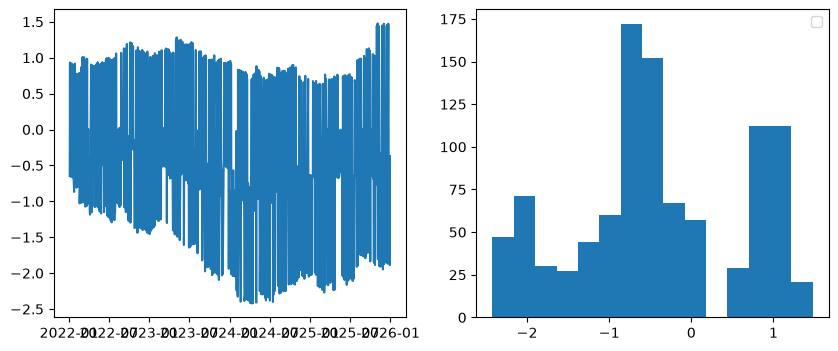

In [55]:
CHRW = stocks.loc[stocks['Ticker'] == 'CHRW', 'log_ret']

fig, ax = plt.subplots(1,2, figsize = (10,4))
ax[0].plot(CHRW)
ax[1].hist(CHRW, bins = 15 )
plt.legend()
plt.show()

1. (1 pt) How many companies have missing inclusion dates (included column)?

In [36]:
comp_no = pd.read_csv('companies/companies_no_subindustry.csv')
print(f'There are {comp_no['included'].isna().sum()} companies with missing inclusion dates.')

There are 45 companies with missing inclusion dates.


(2 pt) Remove companies with missing inclusion dates. Find the oldest and youngest
constituent (in terms of inclusion date), and compute the median age of a constituent
in years (median difference in years between today’s date and date Founded). The
format of the values in Founded column differs. You can unify it by taking the first
4 characters of each entry.
Hint: pd.to_datetime(..., dayfirst=True, errors=’coerce’).

In [38]:
comp_no = comp_no.dropna()
print(f'{comp_no.loc[comp_no['included'].idxmin(), 'Security']} has the oldest inclusion date')
print(f'{comp_no.loc[comp_no['included'].idxmax(), 'Security']} has the youngest inclusion date')



Eastman Chemical Company has the oldest inclusion date
AbbVie has the youngest inclusion date


Compute the number of companies in each of the sectors and visualize proportions (e.g., pie chart).

Part 3 (2 points)
1. (1 pt) Generate four random variables from four different distributions (e.g., Normal,
Uniform, etc.), each with a random number of observations between 100 and 500.
2. (1 pt) Draw a 2x2 grid of plots visualizing the random variables. Use at least 2 of
the following plot types - PDF, CDF, histogram and boxplot.

In [79]:
randSeed = np.random.default_rng(7)
random = randSeed.integers(100, 500, 1)

array([477])

In [80]:
randSeed = np.random.default_rng(7)
randRange = randSeed.random(random)
normDist = randSeed.normal(1, 1, range(random))
standDist = randSeed.standard_normal(0, 1, range(random1))
unifDist = randSeed.uniform(0, 1, range(random))
unif2Dist = randSeed.uniform(1, 2, range(random))

TypeError: only integer scalar arrays can be converted to a scalar index